# Understanding Gradient Descent Through Interactive Visualization
Developed by Anis Koubaa

## Introduction
This notebook provides an interactive visualization of gradient descent algorithm - one of the fundamental optimization techniques in machine learning. We'll use a simple linear regression problem to understand how gradient descent works.

## Learning Objectives
After completing this notebook, you will:
- Understand what gradient descent is and how it works
- Visualize how the algorithm converges to the optimal solution
- Learn the impact of learning rate on model training
- See how gradient descent minimizes the cost function
- Connect theoretical concepts to practical implementation

## The Problem Setup
We'll work with a simple linear regression problem:
1. We have data points that roughly follow a linear pattern
2. Our goal is to find the best-fitting line (y = mx + b)
3. We'll use gradient descent to find the optimal slope (m)
4. For simplicity, we'll keep the intercept (b) fixed at 1

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interactive, FloatSlider, IntSlider
import ipywidgets as widgets

## Data Generation for Linear Regression

This code generates synthetic data for our linear regression example:

In [ ]:
# Generate sample data
np.random.seed(42)
X = np.linspace(0, 10, 20)
y = 2 * X + 1 + np.random.normal(0, 1, 20)

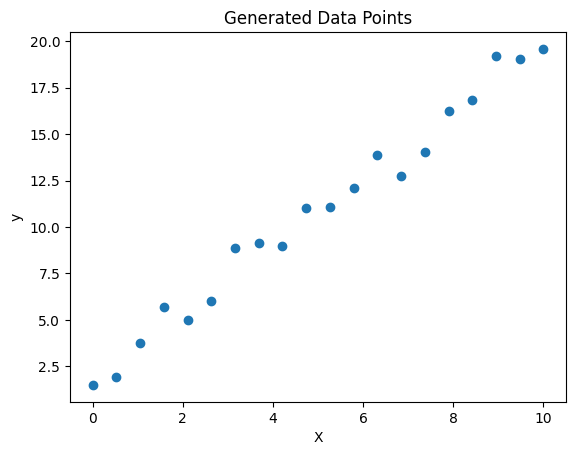

In [ ]:
plt.scatter(X, y)
plt.xlabel('X')
plt.ylabel('y')
plt.title('Generated Data Points')
plt.show()

## Loss Function in Linear Regression

```python
def compute_loss(w, b):
    y_pred = w * X + b  # Linear model: y = wx + b
    return np.mean((y_pred - y) ** 2)
```

### Components:
1. **Model Prediction**: `y_pred = w * X + b`
   - `w`: weight parameter (slope)
   - `X`: input features
   - `b`: bias parameter (intercept)

2. **Mean Squared Error (MSE)**: `np.mean((y_pred - y) ** 2)`
   - Calculates `(prediction - actual)²`
   - Takes mean across all samples
   - Lower loss = better model fit

### Mathematical Form:
$$ \text{Loss} = \frac{1}{n}\sum_{i=1}^{n}(wx_i + b - y_i)^2 $$

where n is the number of training examples.

In [ ]:
#MSE function
def compute_loss(w, b):
    """Compute Mean Squared Error Loss for given weight w and bias b"""
    y_pred = w * X + b  # Linear model: y = wx + b
    return np.mean((y_pred - y) ** 2)

## Computing Gradients for Linear Regression

### Gradient Calculations:

1. **Step 1**: Calculate prediction error
   - `error = (wx + b) - y`

2. **Weight Gradient**: $\frac{\partial \text{Loss}}{\partial w}$
   - Formula: $\frac{2}{n}\sum_{i=1}^{n}(wx_i + b - y_i)x_i$
   - Code: `dw = 2 * np.mean(error * X)`

3. **Bias Gradient**: $\frac{\partial \text{Loss}}{\partial b}$
   - Formula: $\frac{2}{n}\sum_{i=1}^{n}(wx_i + b - y_i)$
   - Code: `db = 2 * np.mean(error)`

These gradients tell us how to adjust w and b to minimize the loss.
- Negative gradient = direction of steepest descent
- Multiply by learning rate to control step size

In [ ]:
def compute_gradients(w, b):
    """
    Compute gradients of Mean Squared Error loss with respect to weight (w) and bias (b).

    This function helps us know how to update our model parameters:
    - How much to change the weight (w)
    - How much to change the bias (b)
    """
    # Step 1: Make predictions with current model
    # For each input X, predict using y = wx + b
    y_pred = w * X + b

    # Step 2: Calculate prediction errors
    # How far off is each prediction from the true value?
    # Positive error = prediction too high
    # Negative error = prediction too low
    errors = y_pred - y

    # Step 3: Calculate weight gradient (dw)
    # - Multiply each error by its corresponding X value
    # - This tells us how the error changes with X
    # - Larger X values have more impact on weight updates
    # - The 2 comes from derivative of squared error
    error_times_x = errors * X
    dw = 2 * np.mean(error_times_x)

    # Step 4: Calculate bias gradient (db)
    # - Use raw errors for bias
    # - Bias affects all predictions equally (doesn't depend on X)
    # - The 2 comes from derivative of squared error
    db = 2 * np.mean(errors)

    # Return how we should adjust w and b:
    # - Negative gradient = we should decrease the parameter
    # - Positive gradient = we should increase the parameter
    return dw, db

## Gradient Descent Visualization Function

This function creates two plots to visualize the learning process:

### Plot 1: Data and Predictions
- Blue dots: Training data points
- Red line: Model's current prediction (y = wx + b)
- Watch how the line adjusts to fit the data better

### Plot 2: Training History
- Green line: Loss over time (should decrease)
- Blue line: Weight (w) evolution
- Red line: Bias (b) evolution

### Training Process:
```python
# Each iteration:
1. Calculate gradients (dw, db)
2. Update parameters:
   w = w - learning_rate * dw
   b = b - learning_rate * db
3. Track progress (loss, w, b)
```

Adjust `learning_rate` and `num_iterations` to see how they affect learning!

In [ ]:
def plot_gradient_descent(learning_rate=0.01, num_iterations=10):
    plt.figure(figsize=(15, 4))

    # Plot 1: Data and Model Predictions (left)
    plt.subplot(1, 3, 1)
    plt.scatter(X, y, color='blue', alpha=0.5, label='Training data', s=50)

    # Initialize parameters
    current_w = 0  # Initial weight
    current_b = 0  # Initial bias

    weights = [current_w]
    biases = [current_b]
    losses = [compute_loss(current_w, current_b)]

    # Training loop
    for i in range(num_iterations):
        dw, db = compute_gradients(current_w, current_b)
        current_w = current_w - learning_rate * dw
        current_b = current_b - learning_rate * db

        weights.append(current_w)
        biases.append(current_b)
        losses.append(compute_loss(current_w, current_b))

    # Plot final prediction line
    y_pred = current_w * X + current_b
    plt.plot(X, y_pred, color='red', linewidth=2,
            label=f'Prediction\n(w={current_w:.2f}, b={current_b:.2f})')
    plt.xlabel('Input (X)', fontsize=10)
    plt.ylabel('Target (y)', fontsize=10)
    plt.title('Model Fitting', fontsize=12)
    plt.legend(fontsize=8)
    plt.grid(True, alpha=0.3)

    # Plot 2: Loss Surface (middle)
    plt.subplot(1, 3, 2)

    # Create mesh grid for weight values
    w_range = np.linspace(-1, 4, 100)
    loss_surface = [compute_loss(w, current_b) for w in w_range]

    # Plot loss surface
    plt.plot(w_range, loss_surface, 'b-', label='Loss Surface', linewidth=2)

    # Plot optimization path
    plt.scatter(weights, [compute_loss(w, current_b) for w in weights],
                color='red', s=100, alpha=0.5, label='Gradient Steps')

    # Add arrows to show descent direction
    for i in range(len(weights)-1):
        plt.arrow(weights[i], compute_loss(weights[i], current_b),
                 weights[i+1] - weights[i],
                 compute_loss(weights[i+1], current_b) - compute_loss(weights[i], current_b),
                 head_width=0.05, head_length=0.1, fc='g', ec='g', length_includes_head=True)

    plt.xlabel('Weight (w)', fontsize=10)
    plt.ylabel('Loss', fontsize=10)
    plt.title('Loss Surface (Quadratic)', fontsize=12)
    plt.legend(fontsize=8)
    plt.grid(True, alpha=0.3)

    # Plot 3: Training History (right)
    plt.subplot(1, 3, 3)
    plt.plot(range(num_iterations + 1), losses, 'g-', label='Loss', linewidth=2)
    plt.plot(range(num_iterations + 1), weights, 'b-', label='Weight (w)', linewidth=2)
    plt.plot(range(num_iterations + 1), biases, 'r-', label='Bias (b)', linewidth=2)
    plt.xlabel('Iteration', fontsize=10)
    plt.ylabel('Value', fontsize=10)
    plt.title('Training Progress', fontsize=12)
    plt.legend(fontsize=8)
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Print results
    print("\nTraining Results:")
    print(f"Final weight (w): {current_w:.4f} (True: 2.0000)")
    print(f"Final bias (b): {current_b:.4f} (True: 1.0000)")
    print(f"Final loss: {compute_loss(current_w, current_b):.4f}")

# Create interactive widgets
interactive_plot = interactive(
    plot_gradient_descent,
    learning_rate=FloatSlider(
        min=0.001, max=0.1, step=0.001,
        value=0.01, description='Learning Rate'
    ),
    num_iterations=IntSlider(
        min=1, max=50, step=1,
        value=10, description='Iterations'
    )
)

display(interactive_plot)

interactive(children=(FloatSlider(value=0.01, description='Learning Rate', max=0.1, min=0.001, step=0.001), In…

In [ ]:
def plot_gradient_descent(learning_rate=0.01, num_iterations=10):
    plt.figure(figsize=(15, 4))

    # Plot 1: Data and Model Predictions (left)
    plt.subplot(1, 3, 1)
    plt.scatter(X, y, color='blue', alpha=0.5, label='Training data', s=50)

    # Initialize parameters
    current_w = 0  # Initial weight
    current_b = 0  # Initial bias

    weights = [current_w]
    biases = [current_b]
    losses = [compute_loss(current_w, current_b)]

    # Training loop
    for i in range(num_iterations):
        dw, db = compute_gradients(current_w, current_b)
        current_w = current_w - learning_rate * dw
        current_b = current_b - learning_rate * db

        weights.append(current_w)
        biases.append(current_b)
        losses.append(compute_loss(current_w, current_b))

    # Plot final prediction line
    y_pred = current_w * X + current_b
    plt.plot(X, y_pred, color='red', linewidth=2,
            label=f'Prediction\n(w={current_w:.2f}, b={current_b:.2f})')
    plt.xlabel('Input (X)', fontsize=10)
    plt.ylabel('Target (y)', fontsize=10)
    plt.title('Model Fitting', fontsize=12)
    plt.legend(fontsize=8)
    plt.grid(True, alpha=0.3)

    # Plot 2: Loss Surface (middle)
    plt.subplot(1, 3, 2)

    # Create mesh grid for weight values
    w_range = np.linspace(-1, 4, 100)
    loss_surface = [compute_loss(w, current_b) for w in w_range]

    # Plot loss surface (normal scale)
    plt.plot(w_range, loss_surface, 'b-', label='Loss Surface', linewidth=2)

    # Plot optimization path
    plt.scatter(weights, [compute_loss(w, current_b) for w in weights],
                color='red', s=100, alpha=0.5, label='Gradient Steps')

    # Add arrows to show descent direction
    for i in range(len(weights)-1):
        plt.arrow(weights[i], compute_loss(weights[i], current_b),
                 weights[i+1] - weights[i],
                 compute_loss(weights[i+1], current_b) - compute_loss(weights[i], current_b),
                 head_width=0.05, head_length=0.1, fc='g', ec='g', length_includes_head=True)

    plt.xlabel('Weight (w)', fontsize=10)
    plt.ylabel('Loss', fontsize=10)
    plt.title('Loss Surface (Quadratic)', fontsize=12)
    plt.legend(fontsize=8)
    plt.grid(True, alpha=0.3)

    # Plot 3: Training History with Log Scale (right)
    plt.subplot(1, 3, 3)

    # Create twin axes for different scales
    ax1 = plt.gca()
    ax2 = ax1.twinx()

    # Plot loss on log scale (green)
    ln1 = ax1.semilogy(range(num_iterations + 1), losses, 'g-',
                      label='Loss (log scale)', linewidth=2)
    ax1.set_ylabel('Loss (log scale)', color='g', fontsize=10)
    ax1.tick_params(axis='y', labelcolor='g')
    ax1.grid(True, alpha=0.3, which="both")

    # Plot parameters on linear scale (blue and red)
    ln2 = ax2.plot(range(num_iterations + 1), weights, 'b-',
                  label='Weight (w)', linewidth=2)
    ln3 = ax2.plot(range(num_iterations + 1), biases, 'r-',
                  label='Bias (b)', linewidth=2)
    ax2.set_ylabel('Parameter Values', fontsize=10)

    # Combine legends from both axes
    lns = ln1 + ln2 + ln3
    labs = [l.get_label() for l in lns]
    ax1.legend(lns, labs, fontsize=8, loc='upper right')

    plt.xlabel('Iteration', fontsize=10)
    plt.title('Training Progress', fontsize=12)

    plt.tight_layout()
    plt.show()

    # Print results
    print("\nTraining Results:")
    print(f"Final weight (w): {current_w:.4f} (True: 2.0000)")
    print(f"Final bias (b): {current_b:.4f} (True: 1.0000)")
    print(f"Final loss: {compute_loss(current_w, current_b):.2e}")  # Scientific notation



In [ ]:
# Create interactive widgets
interactive_plot = interactive(
    plot_gradient_descent,
    learning_rate=FloatSlider(
        min=0.001, max=0.1, step=0.001,
        value=0.01, description='Learning Rate'
    ),
    num_iterations=IntSlider(
        min=1, max=50, step=1,
        value=10, description='Iterations'
    )
)

display(interactive_plot)

interactive(children=(FloatSlider(value=0.01, description='Learning Rate', max=0.1, min=0.001, step=0.001), In…